In [1]:
!pip install -q rouge-score bert-score sentence-transformers scikit-learn matplotlib pandas nltk textstat

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import textstat

from rouge_score import rouge_scorer
from bert_score import score
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score

In [3]:
nltk.download("punkt")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [4]:
df = pd.read_csv("../data/news_summary_multi_model_metrics.csv")

df = df.dropna(subset=[
    "text",
    "ctext",
    "llama3.2_summary",
    "gemma3_4b_summary",
    "qwen3_4b_summary"
])

df.head()

,author,date,headlines,read_more,text,ctext,llama3.2_summary,llama3.2_time_sec,llama3.2_memory_mb,gemma3_4b_summary,gemma3_4b_time_sec,gemma3_4b_memory_mb,qwen3_4b_summary,qwen3_4b_time_sec,qwen3_4b_memory_mb
0,Chhavi Tyagi,"03 Aug 2017,Thursday",Daman & Diu revokes mandatory Rakshabandhan in...,http://www.hindustantimes.com/india-news/raksh...,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,16.48,0.22,Following widespread criticism and social medi...,35.80,0.08,The Daman and Diu administration reversed its ...,69.69,0.09
1,Daisy Mowke,"03 Aug 2017,Thursday",Malaika slams user who trolled her for 'divorc...,http://www.hindustantimes.com/bollywood/malaik...,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,5.86,0.08,Malaika Arora Khan faced online criticism afte...,12.21,0.08,Bollywood actress Malaika Arora Khan faced onl...,36.14,0.08
2,Arshiya Chopra,"03 Aug 2017,Thursday",'Virgin' now corrected to 'Unmarried' in IGIMS...,http://www.hindustantimes.com/patna/bihar-igim...,The Indira Gandhi Institute of Medical Science...,The Indira Gandhi Institute of Medical Science...,Here is a summary of the news article in exact...,4.97,0.08,"Following public outcry, the Indira Gandhi Ins...",12.64,0.07,The Indira Gandhi Institute of Medical Science...,43.06,0.07
3,Sumedha Sehra,"03 Aug 2017,Thursday",Aaj aapne pakad liya: LeT man Dujana before be...,http://indiatoday.intoday.in/story/abu-dujana-...,Lashkar-e-Taiba's Kashmir commander Abu Dujana...,Lashkar-e-Taiba's Kashmir commander Abu Dujana...,Here is a 3-sentence summary of the news artic...,6.13,0.08,Here’s a three-sentence summary of the news ar...,16.60,0.08,Lashkar-e-Taiba commander Abu Dujana was kille...,54.24,0.08
4,Aarushi Maheshwari,"03 Aug 2017,Thursday",Hotel staff to get training to spot signs of s...,http://indiatoday.intoday.in/story/sex-traffic...,Hotels in Maharashtra will train their staff t...,Hotels in Mumbai and other Indian cities are t...,Here is a 3-sentence summary of the news artic...,6.38,0.08,Driven by rising concerns about human traffick...,15.80,0.08,Hotel staff across Mumbai and Indian cities ar...,37.62,0.08


In [5]:
models = {
    "llama": {
        "summary": "llama3.2_summary",
        "time": "llama3.2_time_sec",
        "memory": "llama3.2_memory_mb"
    },
    "gemma": {
        "summary": "gemma3_4b_summary",
        "time": "gemma3_4b_time_sec",
        "memory": "gemma3_4b_memory_mb"
    },
    "qwen": {
        "summary": "qwen3_4b_summary",
        "time": "qwen3_4b_time_sec",
        "memory": "qwen3_4b_memory_mb"
    }
}

In [6]:
rows = []

for index, row in df.iterrows():

    article_length = len(str(row["text"]).split())
    reference_length = len(str(row["ctext"]).split())

    for model, cols in models.items():

        summary = str(row[cols["summary"]])

        rows.append({
            "article_id": index,
            "model": model,
            "text": row["text"],
            "reference": row["ctext"],
            "summary": summary,
            "article_length": article_length,
            "reference_length": reference_length,
            "summary_length": len(summary.split()),
            "execution_time": row[cols["time"]],
            "memory_usage": row[cols["memory"]]
        })

metrics_df = pd.DataFrame(rows)

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08


In [7]:
metrics_df["compression_ratio"] = (
    metrics_df["summary_length"] /
    metrics_df["article_length"]
)

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,compression_ratio
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,1.700000
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,1.133333
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,1.233333
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,1.783333
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,1.100000


In [8]:
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

rouge1 = []
rouge2 = []
rougel = []

for _, row in metrics_df.iterrows():

    scores = scorer.score(
        row["reference"],
        row["summary"]
    )

    rouge1.append(scores["rouge1"].fmeasure)
    rouge2.append(scores["rouge2"].fmeasure)
    rougel.append(scores["rougeL"].fmeasure)

metrics_df["ROUGE-1"] = rouge1
metrics_df["ROUGE-2"] = rouge2
metrics_df["ROUGE-L"] = rougel

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,compression_ratio,ROUGE-1,ROUGE-2,ROUGE-L
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,1.700000,0.321503,0.134172,0.200418
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,1.133333,0.189616,0.077098,0.121896
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,1.233333,0.240535,0.093960,0.151448
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,1.783333,0.300781,0.090196,0.132812
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,1.100000,0.144681,0.029915,0.097872


In [9]:
smooth = SmoothingFunction().method1

bleu = []

for _, row in metrics_df.iterrows():

    bleu.append(
        sentence_bleu(
            [row["reference"].split()],
            row["summary"].split(),
            smoothing_function=smooth
        )
    )

metrics_df["BLEU"] = bleu

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,compression_ratio,ROUGE-1,ROUGE-2,ROUGE-L,BLEU
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,1.700000,0.321503,0.134172,0.200418,0.013020
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,1.133333,0.189616,0.077098,0.121896,0.001355
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,1.233333,0.240535,0.093960,0.151448,0.003971
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,1.783333,0.300781,0.090196,0.132812,0.005664
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,1.100000,0.144681,0.029915,0.097872,0.000200


In [10]:
meteor = []

for _, row in metrics_df.iterrows():

    meteor.append(
        meteor_score(
            [row["reference"].split()],
            row["summary"].split()
        )
    )

metrics_df["METEOR"] = meteor

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,compression_ratio,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,METEOR
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,1.700000,0.321503,0.134172,0.200418,0.013020,0.132565
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,1.133333,0.189616,0.077098,0.121896,0.001355,0.062685
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,1.233333,0.240535,0.093960,0.151448,0.003971,0.095697
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,1.783333,0.300781,0.090196,0.132812,0.005664,0.111473
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,1.100000,0.144681,0.029915,0.097872,0.000200,0.048082


In [11]:
P, R, F = score(
    metrics_df["summary"].tolist(),
    metrics_df["reference"].tolist(),
    model_type="distilroberta-base",
    lang="en",
    verbose=True
)

metrics_df["BERTScore"] = F.numpy()

metrics_df.head()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: distilroberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


calculating scores...
computing bert embedding.


  0%|          | 0/7 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/5 [00:00<?, ?it/s]

done in 172.20 seconds, 1.74 sentences/sec


,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,compression_ratio,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,METEOR,BERTScore
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,1.700000,0.321503,0.134172,0.200418,0.013020,0.132565,0.870304
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,1.133333,0.189616,0.077098,0.121896,0.001355,0.062685,0.868439
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,1.233333,0.240535,0.093960,0.151448,0.003971,0.095697,0.873171
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,1.783333,0.300781,0.090196,0.132812,0.005664,0.111473,0.851699
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,1.100000,0.144681,0.029915,0.097872,0.000200,0.048082,0.834183


In [12]:
encoder = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

reference_embeddings = encoder.encode(
    metrics_df["reference"].tolist(),
    convert_to_numpy=True
)

summary_embeddings = encoder.encode(
    metrics_df["summary"].tolist(),
    convert_to_numpy=True
)

similarity = []

for i in range(len(reference_embeddings)):

    similarity.append(
        cosine_similarity(
            [reference_embeddings[i]],
            [summary_embeddings[i]]
        )[0][0]
    )

metrics_df["Semantic Similarity"] = similarity

metrics_df.head()

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,compression_ratio,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,1.700000,0.321503,0.134172,0.200418,0.013020,0.132565,0.870304,0.840699
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,1.133333,0.189616,0.077098,0.121896,0.001355,0.062685,0.868439,0.815233
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,1.233333,0.240535,0.093960,0.151448,0.003971,0.095697,0.873171,0.815419
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,1.783333,0.300781,0.090196,0.132812,0.005664,0.111473,0.851699,0.645386
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,1.100000,0.144681,0.029915,0.097872,0.000200,0.048082,0.834183,0.702980


In [13]:
lexical_diversity = []

for _, row in metrics_df.iterrows():

    words = row["summary"].lower().split()

    if len(words) == 0:
        lexical_diversity.append(0)
    else:
        lexical_diversity.append(
            len(set(words)) / len(words)
        )

metrics_df["Lexical Diversity"] = lexical_diversity

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,compression_ratio,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity,Lexical Diversity
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,1.700000,0.321503,0.134172,0.200418,0.013020,0.132565,0.870304,0.840699,0.774510
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,1.133333,0.189616,0.077098,0.121896,0.001355,0.062685,0.868439,0.815233,0.911765
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,1.233333,0.240535,0.093960,0.151448,0.003971,0.095697,0.873171,0.815419,0.905405
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,1.783333,0.300781,0.090196,0.132812,0.005664,0.111473,0.851699,0.645386,0.747664
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,1.100000,0.144681,0.029915,0.097872,0.000200,0.048082,0.834183,0.702980,0.863636


In [14]:
readability = []

for _, row in metrics_df.iterrows():

    readability.append(
        textstat.flesch_reading_ease(
            row["summary"]
        )
    )

metrics_df["Readability"] = readability

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,compression_ratio,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity,Lexical Diversity,Readability
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,1.700000,0.321503,0.134172,0.200418,0.013020,0.132565,0.870304,0.840699,0.774510,15.566176
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,1.133333,0.189616,0.077098,0.121896,0.001355,0.062685,0.868439,0.815233,0.911765,-6.521667
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,1.233333,0.240535,0.093960,0.151448,0.003971,0.095697,0.873171,0.815419,0.905405,10.311847
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,1.783333,0.300781,0.090196,0.132812,0.005664,0.111473,0.851699,0.645386,0.747664,27.524922
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,1.100000,0.144681,0.029915,0.097872,0.000200,0.048082,0.834183,0.702980,0.863636,11.459545


In [15]:
coverage = []

for _, row in metrics_df.iterrows():

    reference_words = set(
        row["reference"].lower().split()
    )

    summary_words = set(
        row["summary"].lower().split()
    )

    if len(reference_words) == 0:
        coverage.append(0)
    else:
        coverage.append(
            len(reference_words & summary_words) /
            len(reference_words)
        )

metrics_df["Keyword Coverage"] = coverage

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,...,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity,Lexical Diversity,Readability,Keyword Coverage
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,...,0.321503,0.134172,0.200418,0.013020,0.132565,0.870304,0.840699,0.774510,15.566176,0.181818
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,...,0.189616,0.077098,0.121896,0.001355,0.062685,0.868439,0.815233,0.911765,-6.521667,0.118182
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,...,0.240535,0.093960,0.151448,0.003971,0.095697,0.873171,0.815419,0.905405,10.311847,0.168182
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,...,0.300781,0.090196,0.132812,0.005664,0.111473,0.851699,0.645386,0.747664,27.524922,0.177215
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,...,0.144681,0.029915,0.097872,0.000200,0.048082,0.834183,0.702980,0.863636,11.459545,0.080169


In [16]:
redundancy = []

for _, row in metrics_df.iterrows():

    words = row["summary"].lower().split()

    if len(words) == 0:
        redundancy.append(0)
    else:
        redundancy.append(
            1 - len(set(words)) / len(words)
        )

metrics_df["Redundancy"] = redundancy

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,...,ROUGE-2,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity,Lexical Diversity,Readability,Keyword Coverage,Redundancy
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,...,0.134172,0.200418,0.013020,0.132565,0.870304,0.840699,0.774510,15.566176,0.181818,0.225490
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,...,0.077098,0.121896,0.001355,0.062685,0.868439,0.815233,0.911765,-6.521667,0.118182,0.088235
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,...,0.093960,0.151448,0.003971,0.095697,0.873171,0.815419,0.905405,10.311847,0.168182,0.094595
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,...,0.090196,0.132812,0.005664,0.111473,0.851699,0.645386,0.747664,27.524922,0.177215,0.252336
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,...,0.029915,0.097872,0.000200,0.048082,0.834183,0.702980,0.863636,11.459545,0.080169,0.136364


In [17]:
novelty = []

for _, row in metrics_df.iterrows():

    reference = set(
        row["reference"].lower().split()
    )

    summary = set(
        row["summary"].lower().split()
    )

    if len(summary) == 0:
        novelty.append(0)
    else:
        novelty.append(
            len(summary - reference) /
            len(summary)
        )

metrics_df["Novelty"] = novelty

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,...,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity,Lexical Diversity,Readability,Keyword Coverage,Redundancy,Novelty
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,...,0.200418,0.013020,0.132565,0.870304,0.840699,0.774510,15.566176,0.181818,0.225490,0.493671
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,...,0.121896,0.001355,0.062685,0.868439,0.815233,0.911765,-6.521667,0.118182,0.088235,0.580645
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,...,0.151448,0.003971,0.095697,0.873171,0.815419,0.905405,10.311847,0.168182,0.094595,0.447761
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,...,0.132812,0.005664,0.111473,0.851699,0.645386,0.747664,27.524922,0.177215,0.252336,0.475000
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,...,0.097872,0.000200,0.048082,0.834183,0.702980,0.863636,11.459545,0.080169,0.136364,0.666667


In [18]:
metrics_df.to_csv(
    "../results/metrics_per_article.csv",
    index=False
)

metrics_df.head()

,article_id,model,text,reference,summary,article_length,reference_length,summary_length,execution_time,memory_usage,...,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity,Lexical Diversity,Readability,Keyword Coverage,Redundancy,Novelty
0,0,llama,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,60,364,102,16.48,0.22,...,0.200418,0.013020,0.132565,0.870304,0.840699,0.774510,15.566176,0.181818,0.225490,0.493671
1,0,gemma,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,Following widespread criticism and social medi...,60,364,68,35.80,0.08,...,0.121896,0.001355,0.062685,0.868439,0.815233,0.911765,-6.521667,0.118182,0.088235,0.580645
2,0,qwen,The Administration of Union Territory Daman an...,The Daman and Diu administration on Wednesday ...,The Daman and Diu administration reversed its ...,60,364,74,69.69,0.09,...,0.151448,0.003971,0.095697,0.873171,0.815419,0.905405,10.311847,0.168182,0.094595,0.447761
3,1,llama,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,60,396,107,5.86,0.08,...,0.132812,0.005664,0.111473,0.851699,0.645386,0.747664,27.524922,0.177215,0.252336,0.475000
4,1,gemma,Malaika Arora slammed an Instagram user who tr...,"From her special numbers to TV?appearances, Bo...",Malaika Arora Khan faced online criticism afte...,60,396,66,12.21,0.08,...,0.097872,0.000200,0.048082,0.834183,0.702980,0.863636,11.459545,0.080169,0.136364,0.666667


In [19]:
evaluation = (
    metrics_df
    .groupby("model")
    .agg({
        "ROUGE-1":"mean",
        "ROUGE-2":"mean",
        "ROUGE-L":"mean",
        "BLEU":"mean",
        "METEOR":"mean",
        "BERTScore":"mean",
        "Semantic Similarity":"mean",
        "compression_ratio":"mean",
        "summary_length":"mean",
        "article_length":"mean",
        "reference_length":"mean",
        "execution_time":"mean",
        "memory_usage":"mean",
        "Lexical Diversity":"mean",
        "Readability":"mean",
        "Keyword Coverage":"mean",
        "Redundancy":"mean",
        "Novelty":"mean"
    })
    .round(4)
)

evaluation = evaluation.reset_index()

evaluation

,model,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity,compression_ratio,summary_length,article_length,reference_length,execution_time,memory_usage,Lexical Diversity,Readability,Keyword Coverage,Redundancy,Novelty
0,gemma,0.2770,0.1049,0.1747,0.0119,0.1112,0.8687,0.7916,1.3517,78.89,58.47,349.81,14.2040,0.0741,0.8393,17.2336,0.1772,0.1607,0.5338
1,llama,0.3476,0.1781,0.2237,0.0332,0.1585,0.8781,0.7774,1.5736,91.88,58.47,349.81,5.6834,0.0752,0.8052,33.0092,0.2478,0.1948,0.4069
2,qwen,0.2992,0.1359,0.2025,0.0157,0.1228,0.8768,0.8052,1.2192,71.22,58.47,349.81,42.1386,0.0743,0.8523,24.4339,0.2016,0.1477,0.4227


In [20]:
evaluation.to_csv(
    "../results/evaluation_results.csv",
    index=False
)

evaluation

,model,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity,compression_ratio,summary_length,article_length,reference_length,execution_time,memory_usage,Lexical Diversity,Readability,Keyword Coverage,Redundancy,Novelty
0,gemma,0.2770,0.1049,0.1747,0.0119,0.1112,0.8687,0.7916,1.3517,78.89,58.47,349.81,14.2040,0.0741,0.8393,17.2336,0.1772,0.1607,0.5338
1,llama,0.3476,0.1781,0.2237,0.0332,0.1585,0.8781,0.7774,1.5736,91.88,58.47,349.81,5.6834,0.0752,0.8052,33.0092,0.2478,0.1948,0.4069
2,qwen,0.2992,0.1359,0.2025,0.0157,0.1228,0.8768,0.8052,1.2192,71.22,58.47,349.81,42.1386,0.0743,0.8523,24.4339,0.2016,0.1477,0.4227


In [21]:
statistics = metrics_df.describe().round(4)

statistics

,article_id,article_length,reference_length,summary_length,execution_time,memory_usage,compression_ratio,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity,Lexical Diversity,Readability,Keyword Coverage,Redundancy,Novelty
count,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000,300.0000
mean,49.5000,58.4700,349.8100,80.6633,20.6753,0.0745,1.3815,0.3079,0.1396,0.2003,0.0203,0.1309,0.8745,0.7914,0.8323,24.8922,0.2088,0.1677,0.4544
std,28.9143,2.2993,175.8625,14.7543,16.6215,0.0098,0.2591,0.1096,0.0734,0.0813,0.0325,0.0713,0.0208,0.0846,0.0467,13.6525,0.0897,0.0467,0.1032
min,0.0000,48.0000,79.0000,7.0000,2.0400,0.0700,0.1167,0.0080,0.0000,0.0080,0.0000,0.0047,0.7984,0.0667,0.6737,-9.6144,0.0068,0.0000,0.2381
25%,24.7500,57.7500,235.5000,71.0000,6.3175,0.0700,1.2167,0.2306,0.0879,0.1460,0.0014,0.0805,0.8619,0.7573,0.8016,15.8091,0.1458,0.1363,0.3854
50%,49.5000,60.0000,338.5000,80.0000,14.1750,0.0700,1.3667,0.2964,0.1276,0.1870,0.0061,0.1159,0.8715,0.8013,0.8333,26.7112,0.1941,0.1667,0.4500
75%,74.2500,60.0000,405.2500,90.0000,36.0350,0.0800,1.5555,0.3751,0.1848,0.2453,0.0261,0.1644,0.8840,0.8445,0.8637,32.8380,0.2663,0.1984,0.5221
max,99.0000,60.0000,1133.0000,126.0000,85.2900,0.2200,2.2292,0.6154,0.4046,0.4974,0.1767,0.3942,0.9333,0.9432,1.0000,103.0443,0.5049,0.3263,0.8571


In [22]:
statistics.to_csv(
    "../results/descriptive_statistics.csv"
)

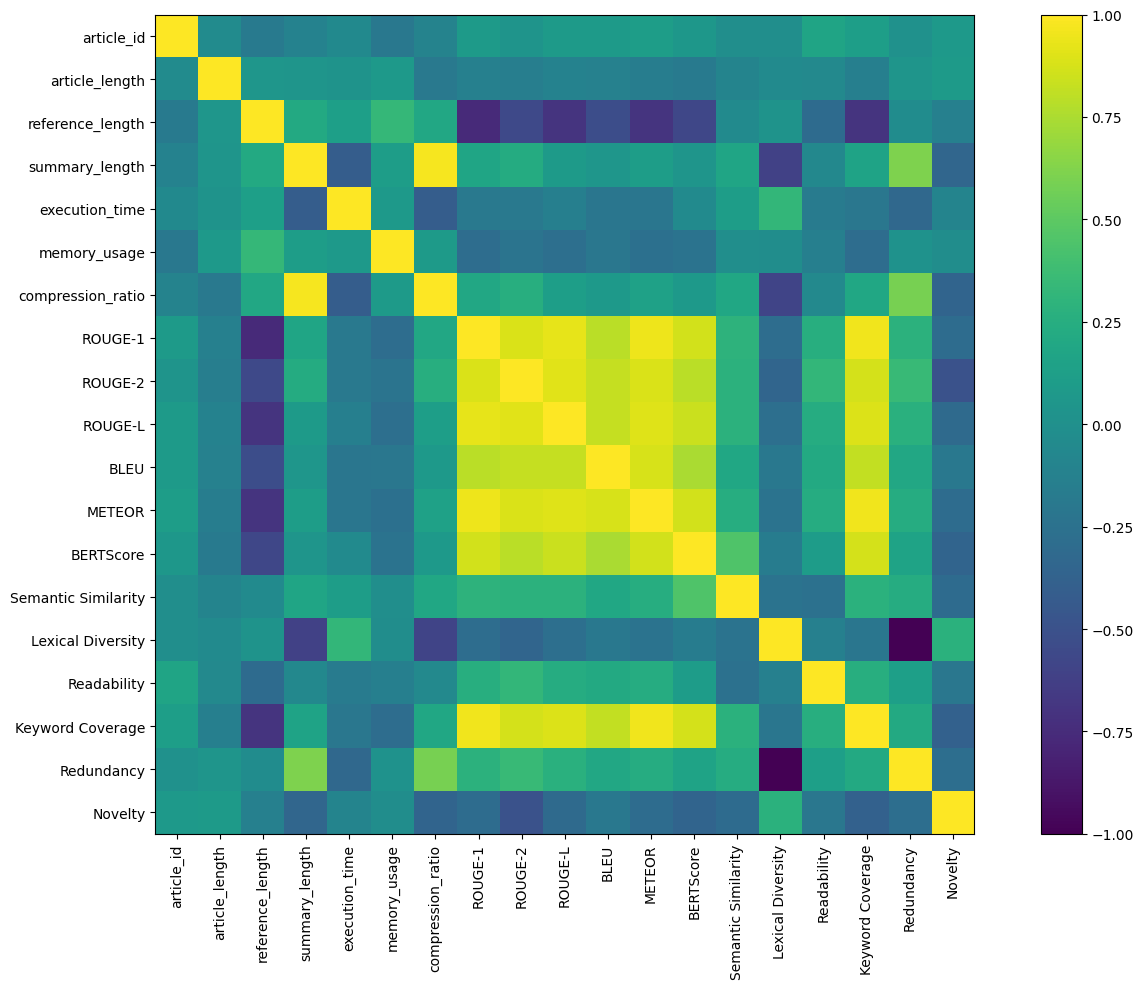

In [23]:
corr = metrics_df.select_dtypes(include="number").corr()

plt.figure(figsize=(14,10))

plt.imshow(corr)

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.colorbar()

plt.tight_layout()

plt.show()

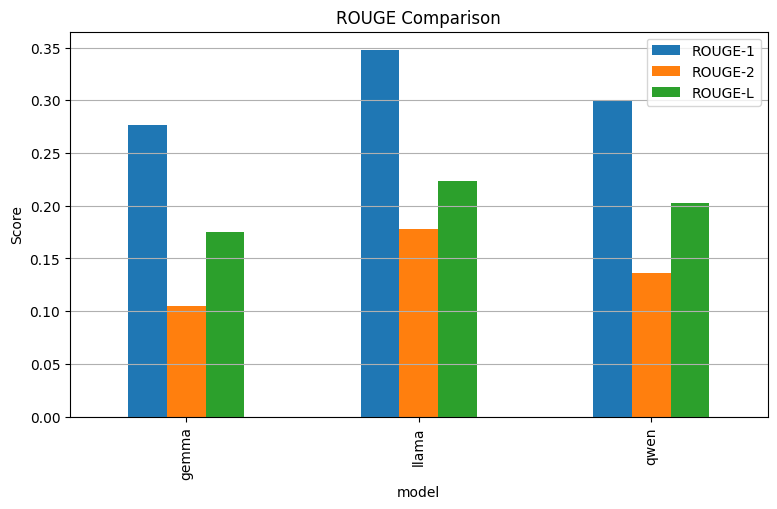

In [24]:
evaluation.plot(
    x="model",
    y=["ROUGE-1","ROUGE-2","ROUGE-L"],
    kind="bar",
    figsize=(9,5)
)

plt.ylabel("Score")
plt.title("ROUGE Comparison")
plt.grid(axis="y")

plt.show()

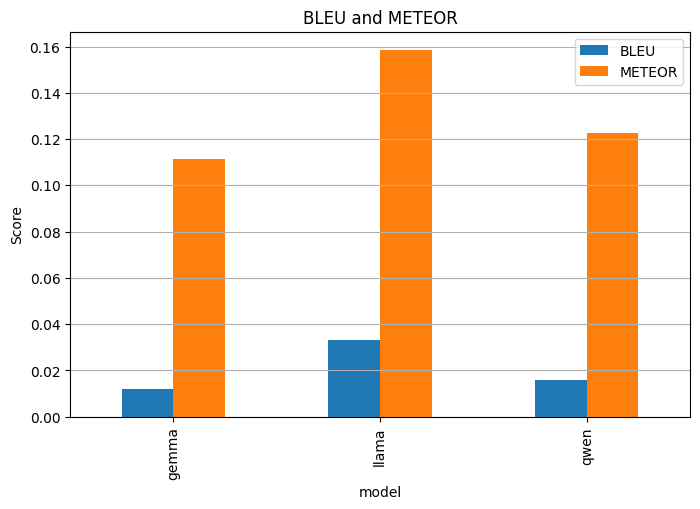

In [25]:
evaluation.plot(
    x="model",
    y=["BLEU","METEOR"],
    kind="bar",
    figsize=(8,5)
)

plt.ylabel("Score")
plt.title("BLEU and METEOR")
plt.grid(axis="y")

plt.show()

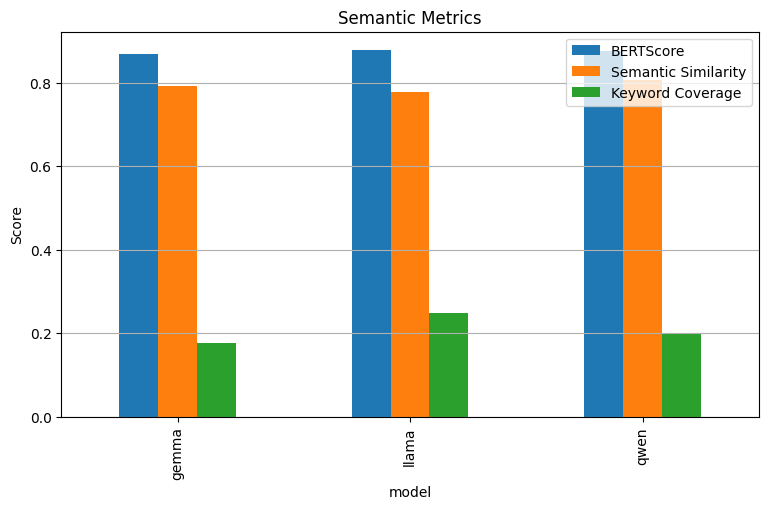

In [26]:
evaluation.plot(
    x="model",
    y=[
        "BERTScore",
        "Semantic Similarity",
        "Keyword Coverage"
    ],
    kind="bar",
    figsize=(9,5)
)

plt.ylabel("Score")
plt.title("Semantic Metrics")
plt.grid(axis="y")

plt.show()

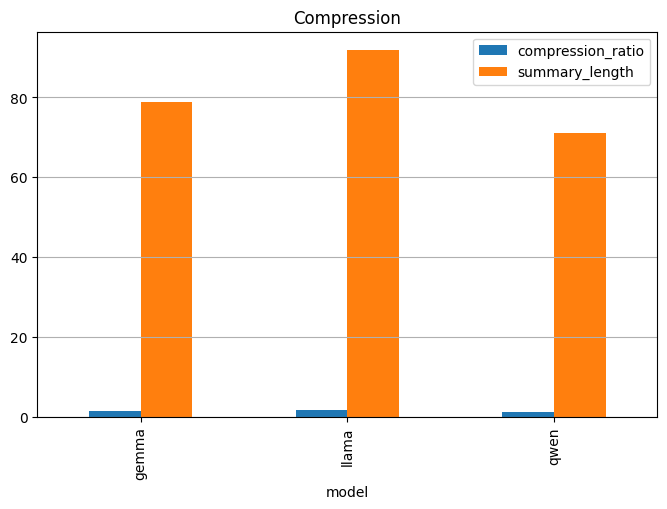

In [27]:
evaluation.plot(
    x="model",
    y=[
        "compression_ratio",
        "summary_length"
    ],
    kind="bar",
    figsize=(8,5)
)

plt.title("Compression")
plt.grid(axis="y")

plt.show()

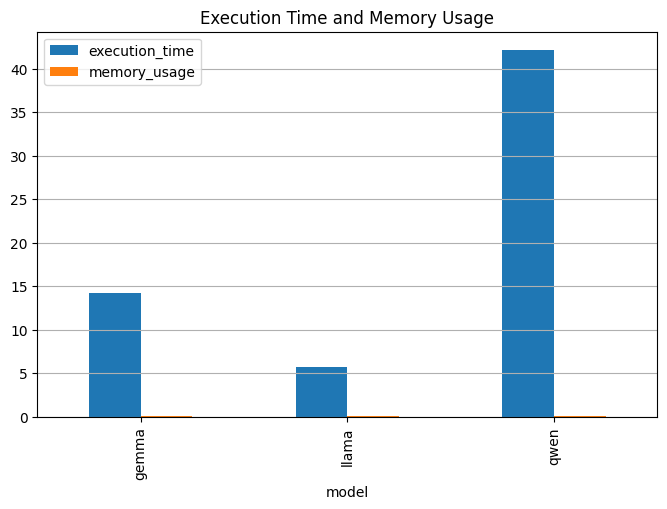

In [28]:
evaluation.plot(
    x="model",
    y=[
        "execution_time",
        "memory_usage"
    ],
    kind="bar",
    figsize=(8,5)
)

plt.title("Execution Time and Memory Usage")
plt.grid(axis="y")

plt.show()

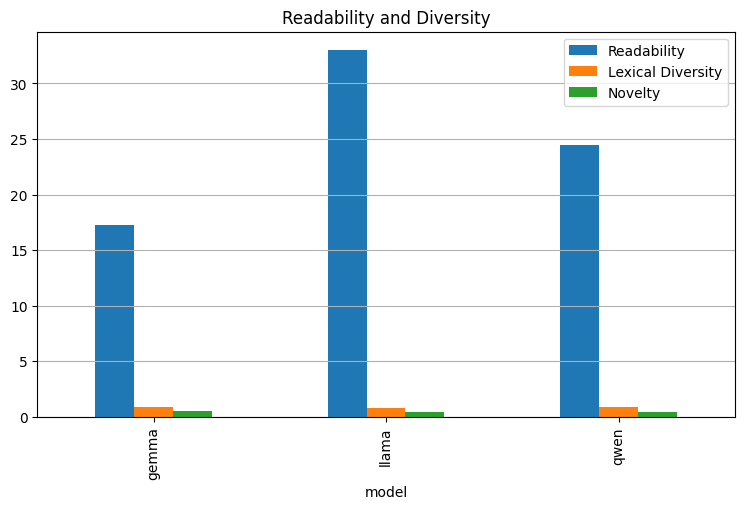

In [29]:
evaluation.plot(
    x="model",
    y=[
        "Readability",
        "Lexical Diversity",
        "Novelty"
    ],
    kind="bar",
    figsize=(9,5)
)

plt.title("Readability and Diversity")
plt.grid(axis="y")

plt.show()

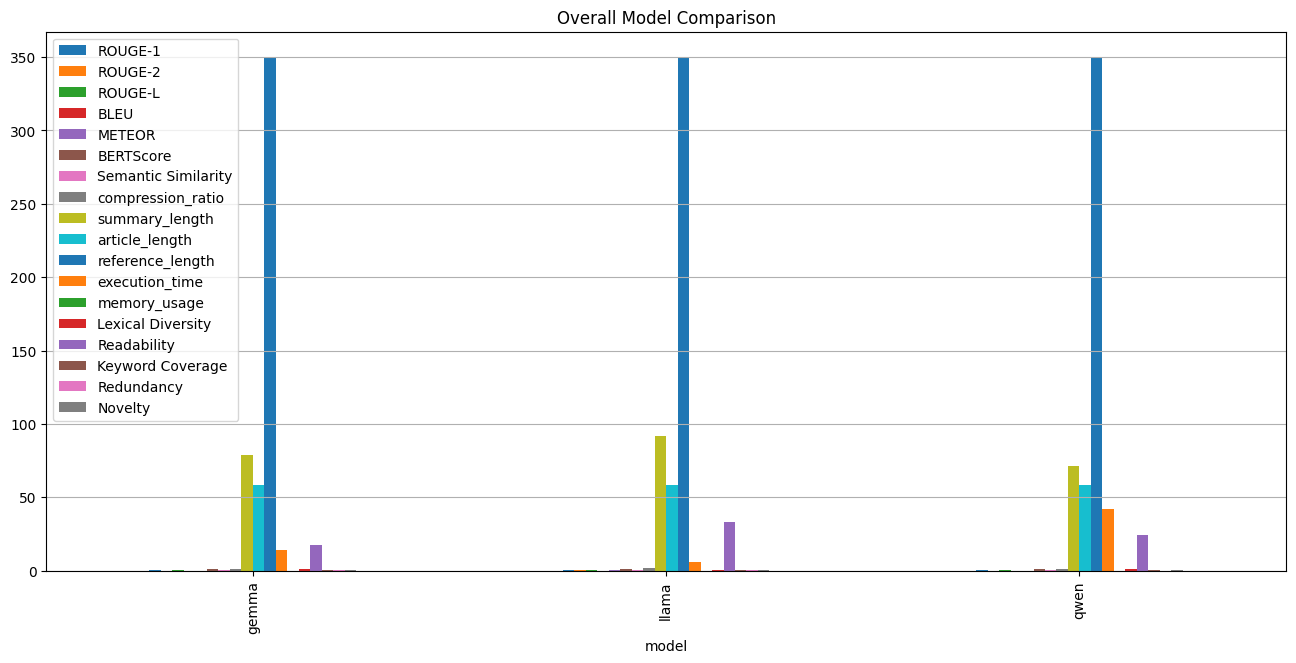

In [30]:
comparison = evaluation.set_index("model")

comparison.plot(
    kind="bar",
    figsize=(16,7)
)

plt.title("Overall Model Comparison")
plt.grid(axis="y")

plt.show()

In [31]:
metrics = [
    "ROUGE-1",
    "ROUGE-2",
    "ROUGE-L",
    "BLEU",
    "METEOR",
    "BERTScore",
    "Semantic Similarity",
    "Keyword Coverage",
    "Lexical Diversity",
    "Readability"
]

best = []

for metric in metrics:

    best.append({
        "Metric": metric,
        "Best Model": evaluation.loc[
            evaluation[metric].idxmax(),
            "model"
        ],
        "Score": evaluation[metric].max()
    })

best_models = pd.DataFrame(best)

best_models

,Metric,Best Model,Score
0,ROUGE-1,llama,0.3476
1,ROUGE-2,llama,0.1781
2,ROUGE-L,llama,0.2237
3,BLEU,llama,0.0332
4,METEOR,llama,0.1585
5,BERTScore,llama,0.8781
6,Semantic Similarity,qwen,0.8052
7,Keyword Coverage,llama,0.2478
8,Lexical Diversity,qwen,0.8523
9,Readability,llama,33.0092


In [32]:
best_models.to_csv(
    "../results/best_models.csv",
    index=False
)

In [33]:
winner = (
    metrics_df
    .loc[
        metrics_df.groupby(
            "article_id"
        )["ROUGE-L"].idxmax()
    ]
)

winner = winner[
    [
        "article_id",
        "model",
        "ROUGE-L"
    ]
]

winner.head()

,article_id,model,ROUGE-L
0,0,llama,0.200418
3,1,llama,0.132812
6,2,llama,0.231818
9,3,llama,0.171103
12,4,llama,0.221884


In [34]:
winner.to_csv(
    "../results/winner_per_article.csv",
    index=False
)

In [35]:
winner["model"].value_counts()

,count
model,
llama,71
qwen,27
gemma,2


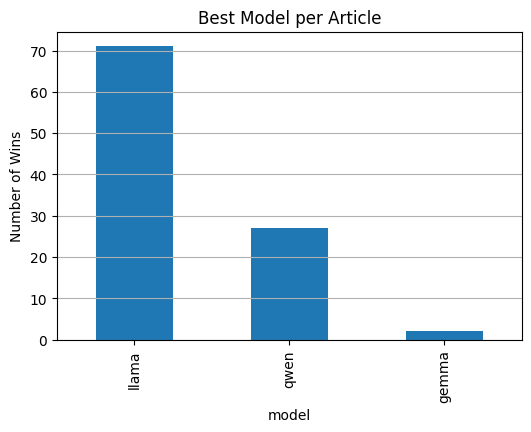

In [36]:
winner["model"].value_counts().plot(
    kind="bar",
    figsize=(6,4)
)

plt.ylabel("Number of Wins")
plt.title("Best Model per Article")

plt.grid(axis="y")

plt.show()

In [37]:
comparison_examples = []

for article in metrics_df["article_id"].unique()[:5]:

    sample = metrics_df[
        metrics_df["article_id"] == article
    ]

    comparison_examples.append({
        "Article": article,
        "Reference": sample.iloc[0]["reference"],
        "Llama": sample[
            sample["model"]=="llama"
        ].iloc[0]["summary"],
        "Gemma": sample[
            sample["model"]=="gemma"
        ].iloc[0]["summary"],
        "Qwen": sample[
            sample["model"]=="qwen"
        ].iloc[0]["summary"]
    })

comparison_examples = pd.DataFrame(
    comparison_examples
)

comparison_examples

,Article,Reference,Llama,Gemma,Qwen
0,0,The Daman and Diu administration on Wednesday ...,Here is a 3-sentence summary of the news artic...,Following widespread criticism and social medi...,The Daman and Diu administration reversed its ...
1,1,"From her special numbers to TV?appearances, Bo...",Here is a 3-sentence summary of the article:\r...,Malaika Arora Khan faced online criticism afte...,Bollywood actress Malaika Arora Khan faced onl...
2,2,The Indira Gandhi Institute of Medical Science...,Here is a summary of the news article in exact...,"Following public outcry, the Indira Gandhi Ins...",The Indira Gandhi Institute of Medical Science...
3,3,Lashkar-e-Taiba's Kashmir commander Abu Dujana...,Here is a 3-sentence summary of the news artic...,Here’s a three-sentence summary of the news ar...,Lashkar-e-Taiba commander Abu Dujana was kille...
4,4,Hotels in Mumbai and other Indian cities are t...,Here is a 3-sentence summary of the news artic...,Driven by rising concerns about human traffick...,Hotel staff across Mumbai and Indian cities ar...


In [38]:
comparison_examples.to_csv(
    "../results/summary_examples.csv",
    index=False
)

<Figure size 800x500 with 0 Axes>

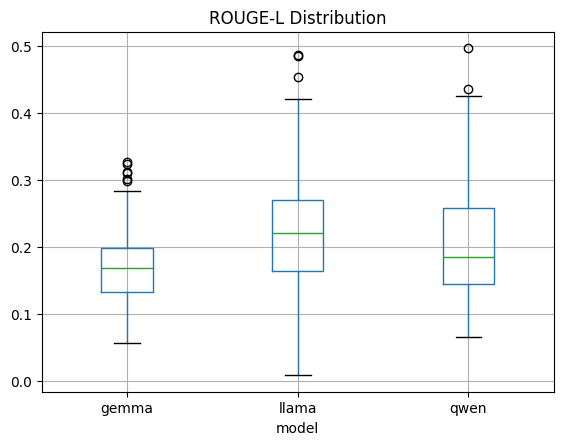

In [39]:
plt.figure(figsize=(8,5))

metrics_df.boxplot(
    column="ROUGE-L",
    by="model"
)

plt.suptitle("")
plt.title("ROUGE-L Distribution")

plt.show()

<Figure size 800x500 with 0 Axes>

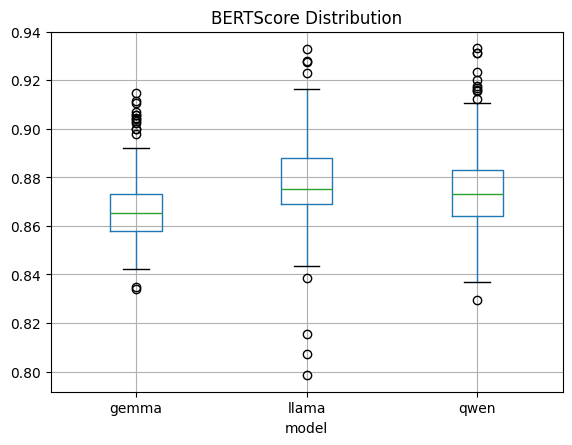

In [40]:
plt.figure(figsize=(8,5))

metrics_df.boxplot(
    column="BERTScore",
    by="model"
)

plt.suptitle("")
plt.title("BERTScore Distribution")

plt.show()

<Figure size 800x500 with 0 Axes>

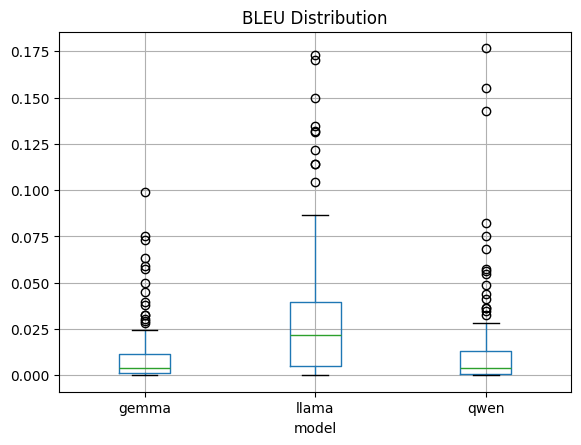

In [41]:
plt.figure(figsize=(8,5))

metrics_df.boxplot(
    column="BLEU",
    by="model"
)

plt.suptitle("")
plt.title("BLEU Distribution")

plt.show()

<Figure size 800x500 with 0 Axes>

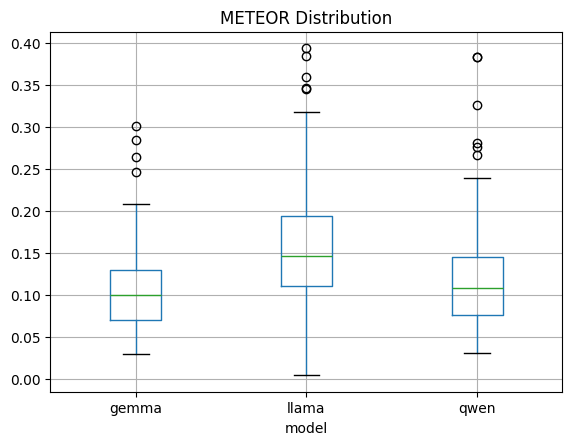

In [42]:
plt.figure(figsize=(8,5))

metrics_df.boxplot(
    column="METEOR",
    by="model"
)

plt.suptitle("")
plt.title("METEOR Distribution")

plt.show()

<Figure size 800x500 with 0 Axes>

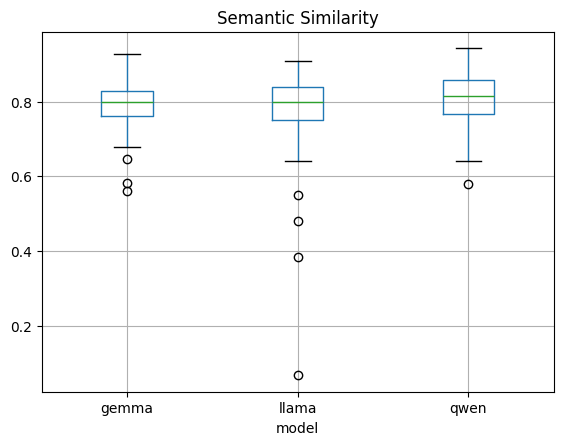

In [43]:
plt.figure(figsize=(8,5))

metrics_df.boxplot(
    column="Semantic Similarity",
    by="model"
)

plt.suptitle("")
plt.title("Semantic Similarity")

plt.show()

<Figure size 800x500 with 0 Axes>

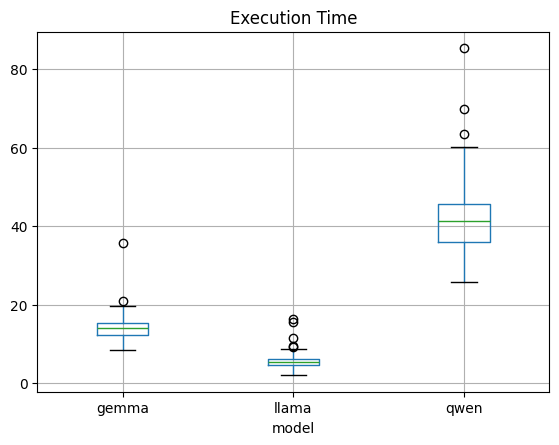

In [44]:
plt.figure(figsize=(8,5))

metrics_df.boxplot(
    column="execution_time",
    by="model"
)

plt.suptitle("")
plt.title("Execution Time")

plt.show()

<Figure size 800x500 with 0 Axes>

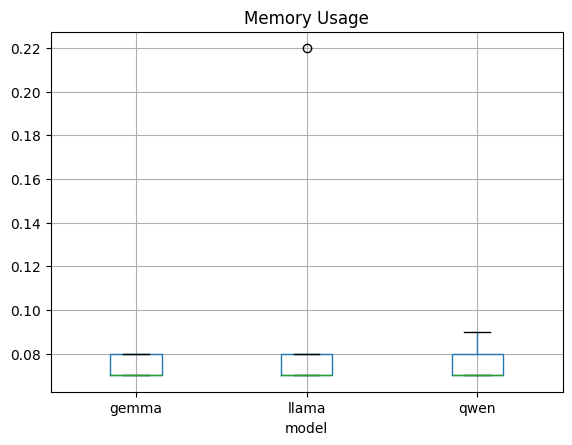

In [45]:
plt.figure(figsize=(8,5))

metrics_df.boxplot(
    column="memory_usage",
    by="model"
)

plt.suptitle("")
plt.title("Memory Usage")

plt.show()

In [46]:
print(evaluation)

print(best_models)

print(statistics)

   model  ROUGE-1  ROUGE-2  ROUGE-L    BLEU  METEOR  BERTScore  \
0  gemma   0.2770   0.1049   0.1747  0.0119  0.1112     0.8687   
1  llama   0.3476   0.1781   0.2237  0.0332  0.1585     0.8781   
2   qwen   0.2992   0.1359   0.2025  0.0157  0.1228     0.8768   

   Semantic Similarity  compression_ratio  summary_length  article_length  \
0               0.7916             1.3517           78.89           58.47   
1               0.7774             1.5736           91.88           58.47   
2               0.8052             1.2192           71.22           58.47   

   reference_length  execution_time  memory_usage  Lexical Diversity  \
0            349.81         14.2040        0.0741             0.8393   
1            349.81          5.6834        0.0752             0.8052   
2            349.81         42.1386        0.0743             0.8523   

   Readability  Keyword Coverage  Redundancy  Novelty  
0      17.2336            0.1772      0.1607   0.5338  
1      33.0092           

In [47]:
ranking = evaluation.copy()

ranking["Overall Score"] = (
    ranking["ROUGE-L"] +
    ranking["BLEU"] +
    ranking["METEOR"] +
    ranking["BERTScore"] +
    ranking["Semantic Similarity"]
) / 5

ranking = ranking.sort_values(
    "Overall Score",
    ascending=False
)

ranking

,model,ROUGE-1,ROUGE-2,ROUGE-L,BLEU,METEOR,BERTScore,Semantic Similarity,compression_ratio,summary_length,article_length,reference_length,execution_time,memory_usage,Lexical Diversity,Readability,Keyword Coverage,Redundancy,Novelty,Overall Score
1,llama,0.3476,0.1781,0.2237,0.0332,0.1585,0.8781,0.7774,1.5736,91.88,58.47,349.81,5.6834,0.0752,0.8052,33.0092,0.2478,0.1948,0.4069,0.41418
2,qwen,0.2992,0.1359,0.2025,0.0157,0.1228,0.8768,0.8052,1.2192,71.22,58.47,349.81,42.1386,0.0743,0.8523,24.4339,0.2016,0.1477,0.4227,0.40460
0,gemma,0.2770,0.1049,0.1747,0.0119,0.1112,0.8687,0.7916,1.3517,78.89,58.47,349.81,14.2040,0.0741,0.8393,17.2336,0.1772,0.1607,0.5338,0.39162


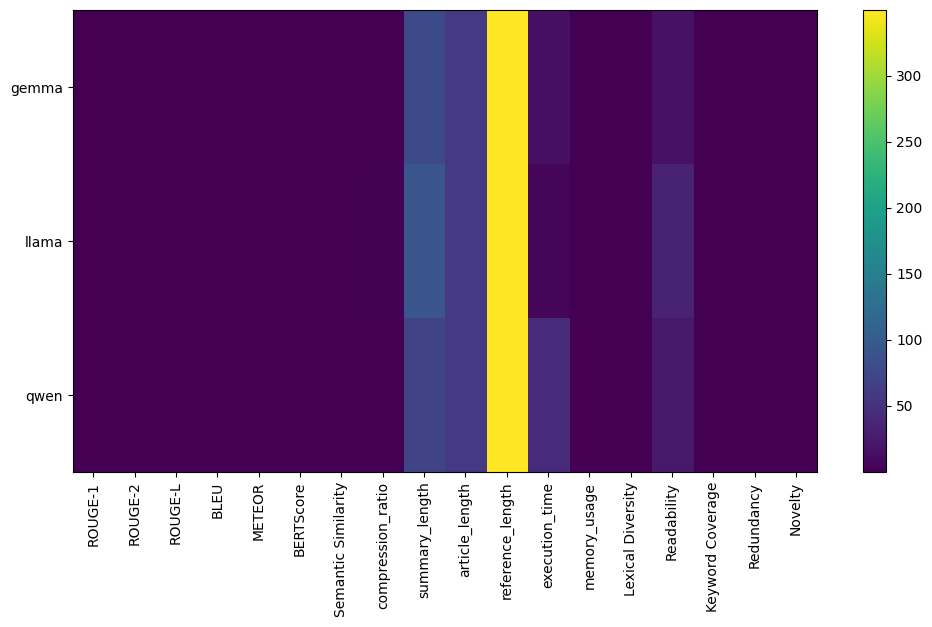

In [48]:
plt.figure(figsize=(12,6))

plt.imshow(
    evaluation.set_index("model"),
    aspect="auto"
)

plt.xticks(
    range(len(evaluation.columns)-1),
    evaluation.columns[1:],
    rotation=90
)

plt.yticks(
    range(len(evaluation)),
    evaluation["model"]
)

plt.colorbar()

plt.show()

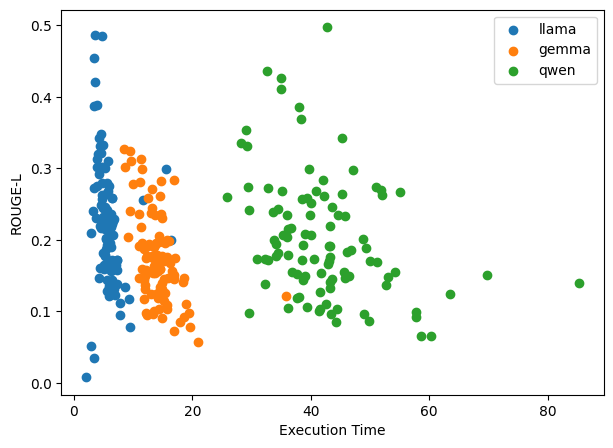

In [49]:
plt.figure(figsize=(7,5))

for model in metrics_df["model"].unique():

    sample = metrics_df[
        metrics_df["model"]==model
    ]

    plt.scatter(
        sample["execution_time"],
        sample["ROUGE-L"],
        label=model
    )

plt.legend()

plt.xlabel("Execution Time")

plt.ylabel("ROUGE-L")

plt.show()

In [58]:
!pip install -q pytorch-tabular

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.8/165.8 kB 504.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.4/852.4 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.3/165.3 kB 7.6 MB/s eta 0:00:00


In [59]:
from sklearn.model_selection import train_test_split

tab_df = metrics_df.copy()

tab_df["model"] = tab_df["model"].map({
    "llama":0,
    "gemma":1,
    "qwen":2
})

features = [
    "model",
    "article_length",
    "reference_length",
    "summary_length",
    "compression_ratio",
    "execution_time",
    "memory_usage",
    "Lexical Diversity",
    "Readability",
    "Keyword Coverage",
    "Redundancy",
    "Novelty"
]

target = "ROUGE-L"

train_df, test_df = train_test_split(
    tab_df,
    test_size=0.2,
    random_state=42
)

In [60]:
from pytorch_tabular import TabularModel
from pytorch_tabular.models import FTTransformerConfig
from pytorch_tabular.config import DataConfig, TrainerConfig, OptimizerConfig

In [61]:
data_config = DataConfig(
    target=[target],
    continuous_cols=features
)

trainer_config = TrainerConfig(
    batch_size=64,
    max_epochs=50
)

optimizer_config = OptimizerConfig()

model_config = FTTransformerConfig(
    task="regression"
)

In [62]:
tabular_model = TabularModel(
    data_config=data_config,
    model_config=model_config,
    optimizer_config=optimizer_config,
    trainer_config=trainer_config
)

2026-06-30 15:34:59,507 - {pytorch_tabular.tabular_model:145} - INFO - Experiment Tracking is turned off


In [63]:
tabular_model.fit(
    train=train_df,
    validation=test_df
)

INFO:lightning_fabric.utilities.seed:Seed set to 42
2026-06-30 15:34:59,595 - {pytorch_tabular.tabular_model:547} - INFO - Preparing the DataLoaders
2026-06-30 15:34:59,616 - {pytorch_tabular.tabular_datamodule:527} - INFO - Setting up the datamodule for regression task
/usr/local/lib/python3.12/dist-packages/pytorch_tabular/tabular_datamodule.py:388: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.01535919  1.21337595 -1.24409433  1.21337595  1.21337595 -1.24409433
 -0.01535919 -0.01535919  1.21337595 -1.24409433 -1.24409433 -1.24409433
  1.21337595 -0.01535919 -1.24409433 -1.24409433 -0.01535919 -1.24409433
 -1.24409433 -1.24409433 -0.01535919 -0.01535919 -0.01535919 -0.01535919
 -0.01535919 -1.24409433 -0.01535919 -1.24409433 -1.24409433 -0.01535919
  1.21337595  1.21337595  1.21337595  1.21337595 -0.01535919 -0.01535919
  1.21337595 -1.24409433 -0.01535919 -0.01535919 -1.24409433 -1.24409433
 -0.01535919 -1.2

┏━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name             ┃ Type                  ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ _backbone        │ FTTransformerBackbone │  271 K │ train │     0 │
│ 1 │ _embedding_layer │ Embedding2dLayer      │    792 │ train │     0 │
│ 2 │ _head            │ LinearHead            │     33 │ train │     0 │
│ 3 │ loss             │ MSELoss               │      0 │ train │     0 │
└───┴──────────────────┴───────────────────────┴────────┴───────┴───────┘

Trainable params: 272 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 272 K                                                                                                
Total estimated model params size (MB): 1.089                                                                      
Modules in train mode: 122                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is 
set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/loops/fit_loop.py:321: The number of training batches (4)
is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you 
want to see logs for the training epoch.

2026-06-30 15:35:24,499 - {pytorch_tabular.tabular_model:690} - INFO - Training the model completed
2026-06-30 15:35:24,501 - {pytorch_tabular.tabular_model:1531} - INFO - Loading the best model


In [64]:
pred = tabular_model.predict(test_df)

pred.head()

/usr/local/lib/python3.12/dist-packages/pytorch_tabular/tabular_datamodule.py:392: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 1.21337595  1.21337595  1.21337595 -1.24409433  1.21337595 -0.01535919
 -0.01535919 -0.01535919  1.21337595 -0.01535919 -1.24409433 -1.24409433
  1.21337595 -1.24409433  1.21337595  1.21337595 -0.01535919 -0.01535919
 -0.01535919 -1.24409433 -1.24409433  1.21337595 -1.24409433 -0.01535919
  1.21337595 -1.24409433  1.21337595 -0.01535919 -0.01535919 -0.01535919
  1.21337595  1.21337595 -1.24409433 -1.24409433  1.21337595  1.21337595
 -0.01535919 -1.24409433 -0.01535919 -0.01535919 -1.24409433 -0.01535919
 -0.01535919 -1.24409433  1.21337595 -1.24409433 -1.24409433 -0.01535919
 -1.24409433 -1.24409433 -1.24409433 -1.24409433  1.21337595 -1.24409433
 -1.24409433  1.21337595 -0.01535919  1.21337595 -1.24409433 -0.01535919]' has dtype incompatible with int64, please explicitly cast to a comp

,ROUGE-L_prediction
203,0.294210
266,0.254540
152,0.467975
9,0.118305
233,0.222452


In [66]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pred_col = "ROUGE-L_prediction"

mae = mean_absolute_error(
    test_df[target],
    pred[pred_col]
)

rmse = mean_squared_error(
    test_df[target],
    pred[pred_col]
) ** 0.5

r2 = r2_score(
    test_df[target],
    pred[pred_col]
)

print("MAE =", round(mae,4))
print("RMSE =", round(rmse,4))
print("R² =", round(r2,4))

MAE = 0.0845
RMSE = 0.104
R² = -1.0701


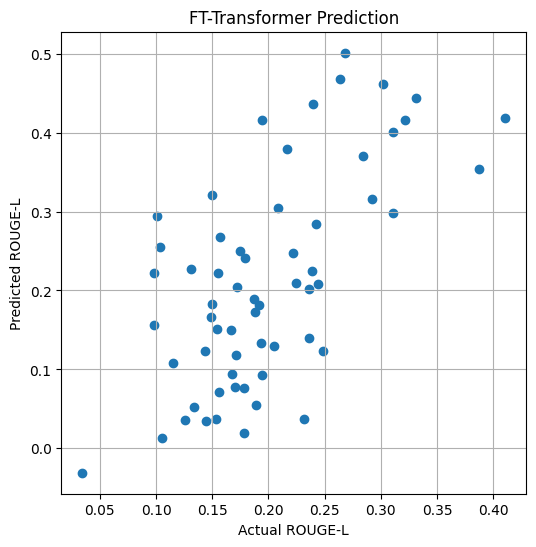

In [68]:
plt.figure(figsize=(6,6))

plt.scatter(
    test_df[target],
    pred[pred_col]
)

plt.xlabel("Actual ROUGE-L")
plt.ylabel("Predicted ROUGE-L")
plt.title("FT-Transformer Prediction")

plt.grid()

plt.show()

In [69]:
performance = pd.DataFrame({
    "Metric":["MAE","RMSE","R2"],
    "Value":[mae,rmse,r2]
})

performance

,Metric,Value
0,MAE,0.084514
1,RMSE,0.104044
2,R2,-1.070134


In [70]:
performance.to_csv(
    "../results/tabular_model_results.csv",
    index=False
)